In [ ]:
#Task 2 (Classification Evaluation & Metrics Analysis)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, precision_score,
                             recall_score, f1_score, accuracy_score, roc_curve, roc_auc_score)

sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True)
SEED = 42

In [ ]:
#1. Rebuild the model & generate probability predictions

df = load_breast_cancer(as_frame=True).frame
df["target"] = 1 - df["target"]                     # 1 = malignant
X, y = df.drop(columns="target"), df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_s, y_train)
y_prob = model.predict_proba(X_test_s)[:, 1]        # P(malignant)
y_pred = (y_prob >= 0.5).astype(int)                # default threshold
print("Test samples:", len(y_test))
print("First 5 probabilities:", np.round(y_prob[:5], 4))

Test samples: 114
First 5 probabilities: [4.000e-04 1.000e+00 4.260e-02 5.762e-01 5.092e-01]


TP = 39 | TN = 71 | FP = 1 | FN = 3


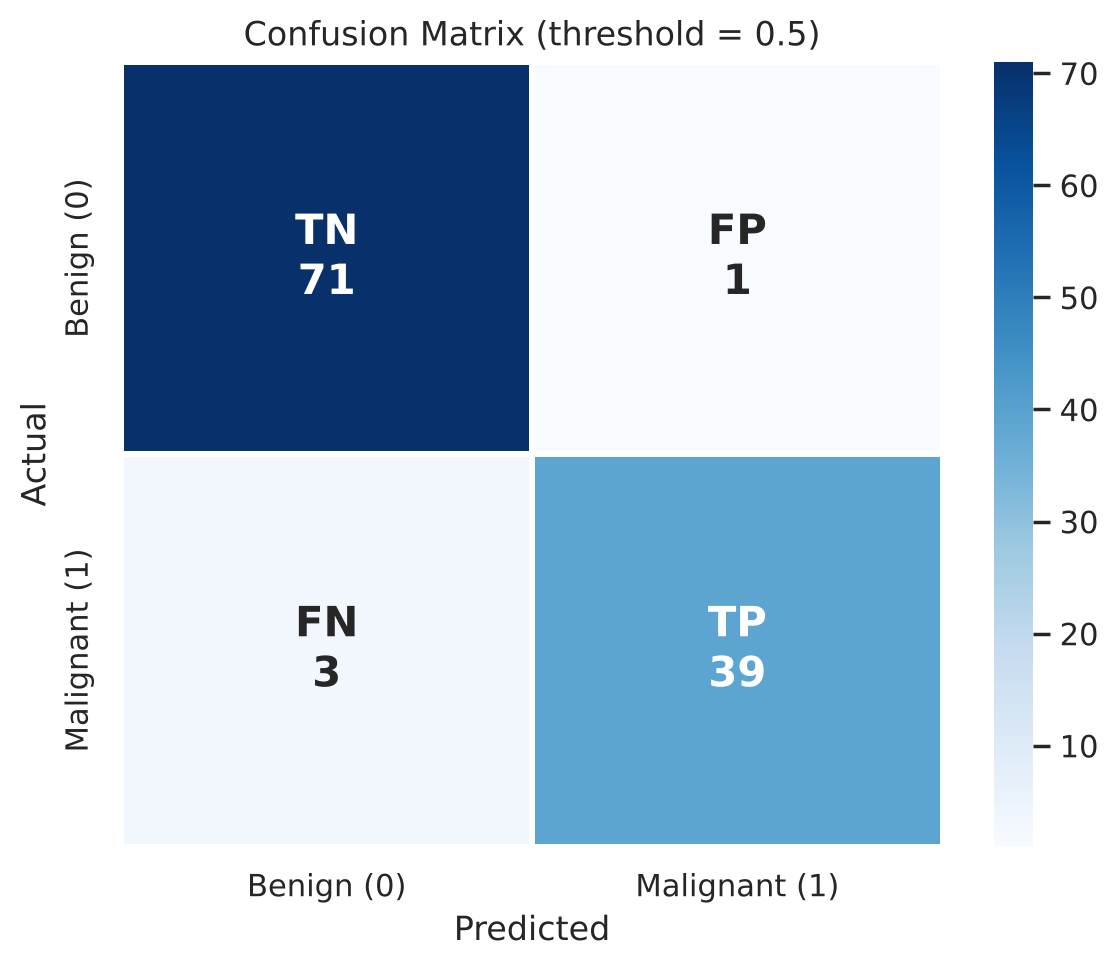

In [ ]:
#2. Confusion matrix (threshold = 0.5)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TP = {tp} | TN = {tn} | FP = {fp} | FN = {fn}")

labels = np.array([[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=True, linewidths=2, linecolor="white",
            xticklabels=["Benign (0)", "Malignant (1)"], yticklabels=["Benign (0)", "Malignant (1)"],
            annot_kws={"size": 15, "weight": "bold"}, ax=ax)
ax.set(xlabel="Predicted", ylabel="Actual", title="Confusion Matrix (threshold = 0.5)")
plt.tight_layout(); plt.savefig("figures/confusion_matrix.png", dpi=150); plt.show()

In [ ]:
#3. Precision, Recall, F1 — manual vs scikit-learn
def manual_metrics(tp, tn, fp, fn):
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    accuracy  = (tp + tn) / (tp + tn + fp + fn)
    return dict(Accuracy=accuracy, Precision=precision, Recall=recall, F1=f1)

man = manual_metrics(tp, tn, fp, fn)
skl = dict(Accuracy=accuracy_score(y_test, y_pred), Precision=precision_score(y_test, y_pred),
           Recall=recall_score(y_test, y_pred), F1=f1_score(y_test, y_pred))

comparison = pd.DataFrame({"Manual": man, "scikit-learn": skl})
comparison["Match"] = np.isclose(comparison["Manual"], comparison["scikit-learn"])
comparison.round(4)

,Manual,scikit-learn,Match
Accuracy,0.9649,0.9649,True
Precision,0.9750,0.9750,True
Recall,0.9286,0.9286,True
F1,0.9512,0.9512,True


In [ ]:
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"], digits=4))

              precision    recall  f1-score   support

      Benign     0.9595    0.9861    0.9726        72
   Malignant     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114



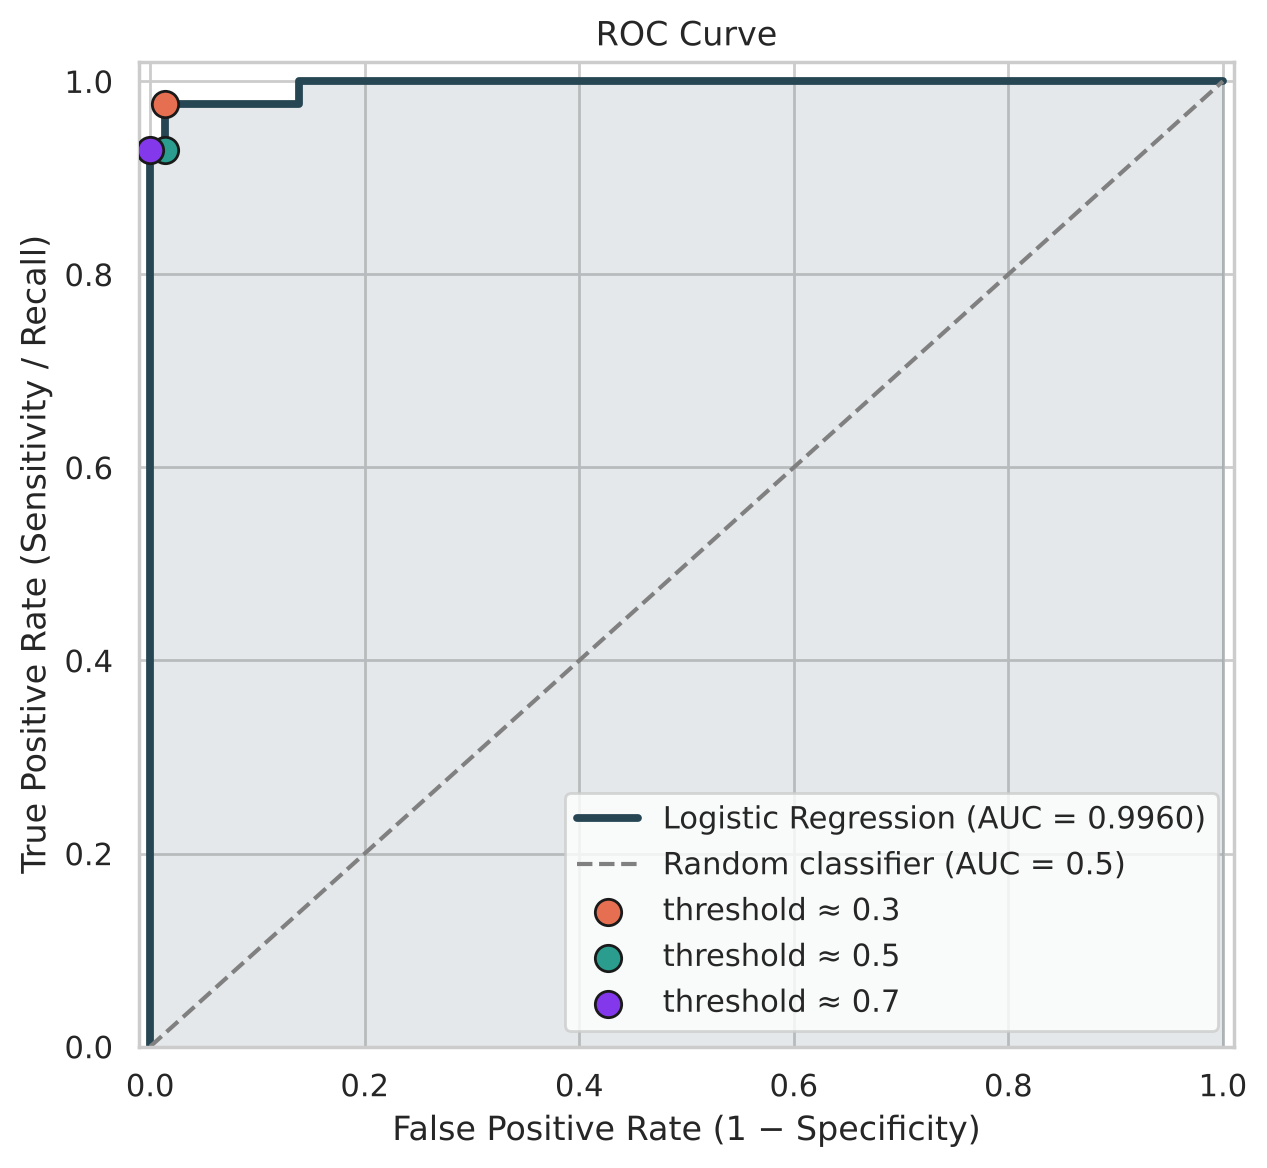

AUC = 0.9960


In [ ]:
#4. ROC curve & AUC
fpr, tpr, thr = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, lw=2.8, color="#264653", label=f"Logistic Regression (AUC = {auc:.4f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random classifier (AUC = 0.5)")
ax.fill_between(fpr, tpr, alpha=0.12, color="#264653")
for t, c in [(0.3, "#e76f51"), (0.5, "#2a9d8f"), (0.7, "#8338ec")]:
    i = np.argmin(np.abs(thr - t))
    ax.scatter(fpr[i], tpr[i], s=90, color=c, edgecolor="k", zorder=5, label=f"threshold ≈ {t}")
ax.set(xlabel="False Positive Rate (1 − Specificity)", ylabel="True Positive Rate (Sensitivity / Recall)",
       title="ROC Curve", xlim=(-0.01, 1.01), ylim=(0, 1.02))
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig("figures/roc_auc_curve.png", dpi=150); plt.show()
print(f"AUC = {auc:.4f}")

## 5. Threshold adjustment: 0.3 vs 0.5 vs 0.7

In [ ]:
#5. Threshold adjustment: 0.3 vs 0.5 vs 0.7
rows, cms = [], {}
for t in [0.3, 0.5, 0.7]:
    pred_t = (y_prob >= t).astype(int)
    c = confusion_matrix(y_test, pred_t); cms[t] = c
    tn_, fp_, fn_, tp_ = c.ravel()
    m = manual_metrics(tp_, tn_, fp_, fn_)
    rows.append(dict(Threshold=t, TP=tp_, FP=fp_, FN=fn_, TN=tn_, **m))
thr_df = pd.DataFrame(rows).set_index("Threshold")
thr_df.round(4)

,TP,FP,FN,TN,Accuracy,Precision,Recall,F1
Threshold,,,,,,,,
0.3,41,1,1,71,0.9825,0.9762,0.9762,0.9762
0.5,39,1,3,71,0.9649,0.9750,0.9286,0.9512
0.7,38,0,4,72,0.9649,1.0000,0.9048,0.9500


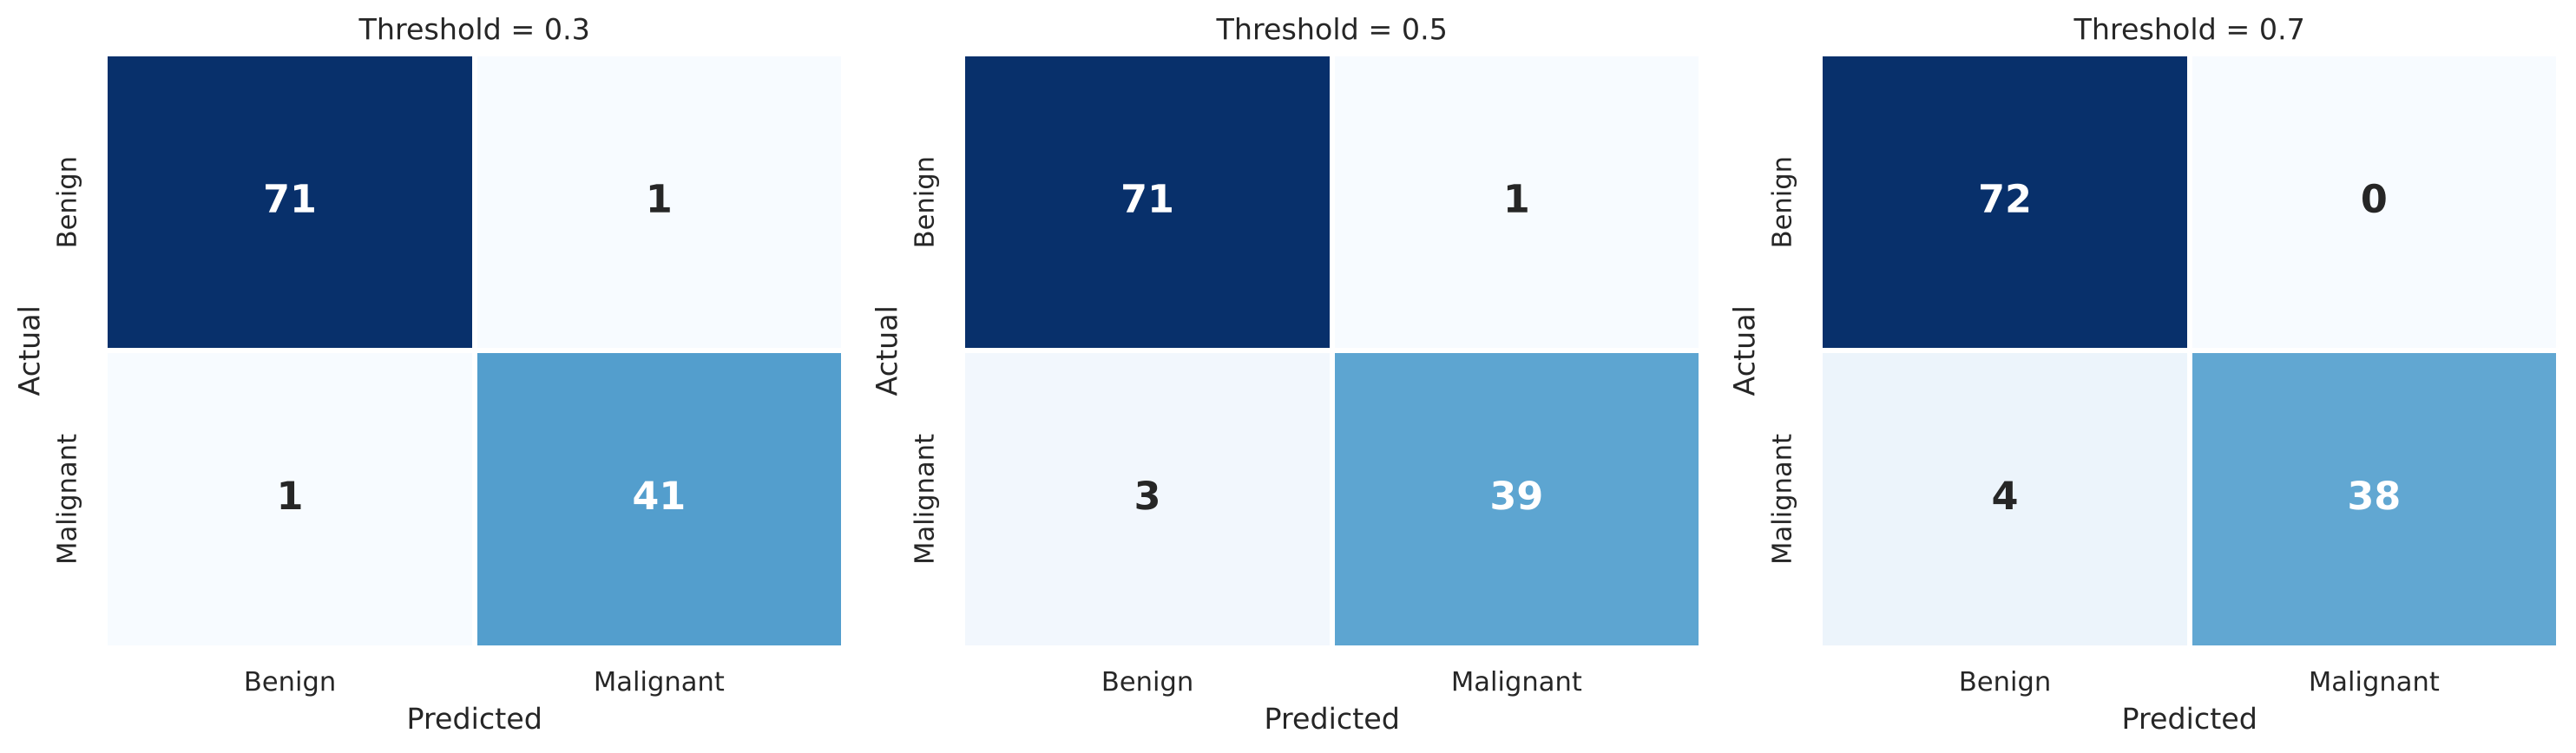

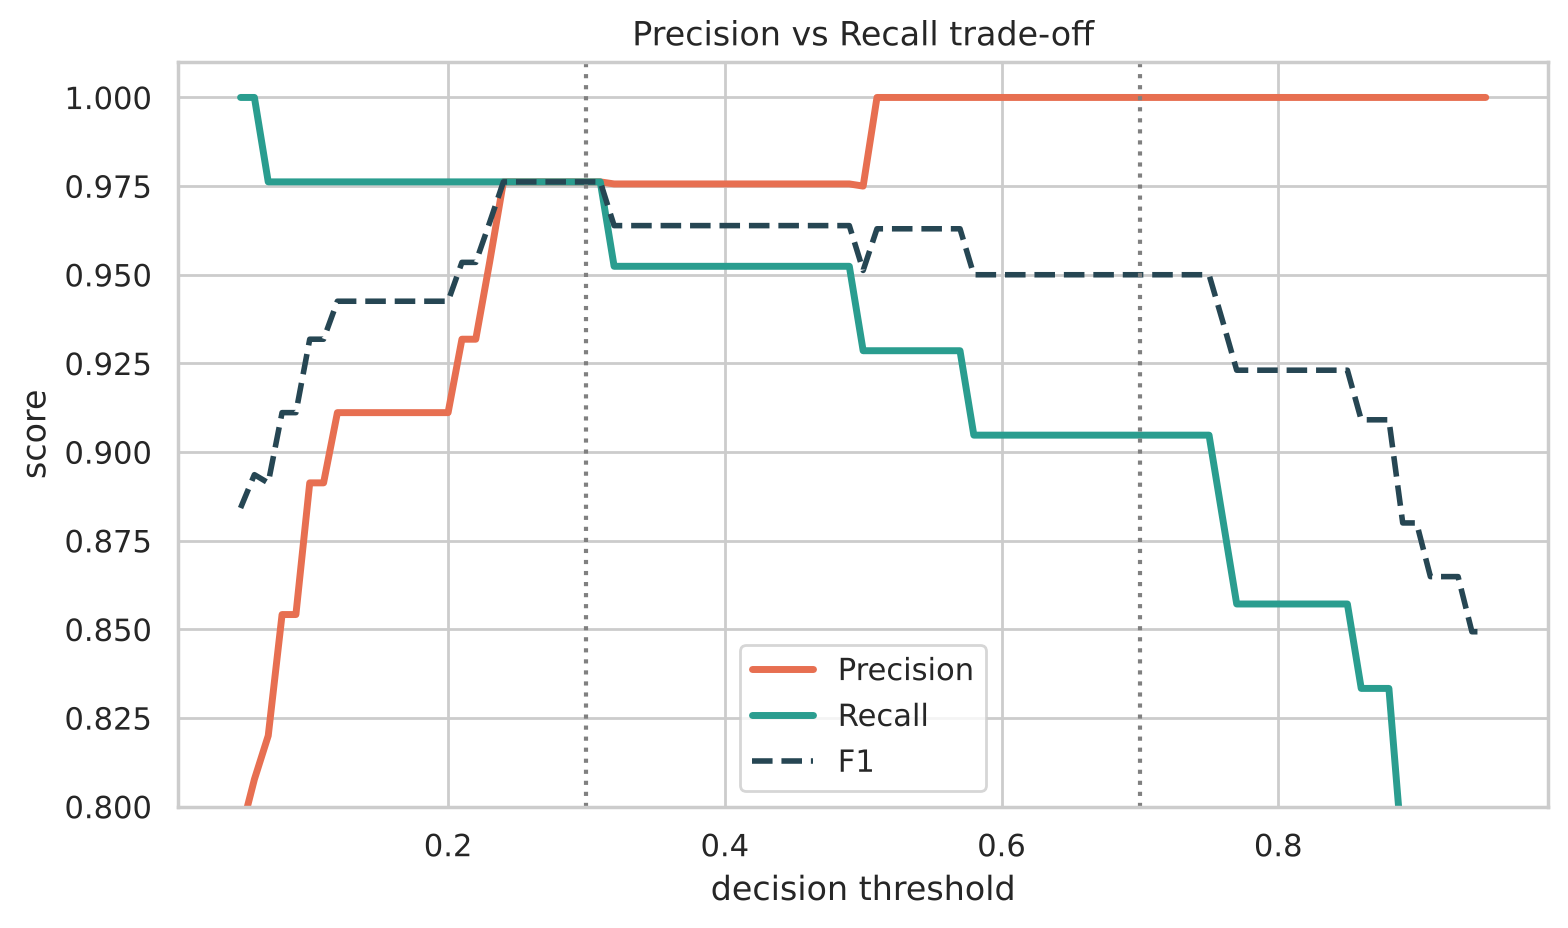

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (t, c) in zip(axes, cms.items()):
    sns.heatmap(c, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"],
                annot_kws={"size": 16, "weight": "bold"}, ax=ax)
    ax.set(title=f"Threshold = {t}", xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.savefig("figures/threshold_confusion_matrices.png", dpi=150); plt.show()

# Precision / Recall / F1 as a function of threshold
ts = np.linspace(0.05, 0.95, 91)
P = [precision_score(y_test, y_prob >= t, zero_division=0) for t in ts]
R = [recall_score(y_test, y_prob >= t) for t in ts]
F = [f1_score(y_test, y_prob >= t, zero_division=0) for t in ts]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(ts, P, lw=2.5, label="Precision", color="#e76f51"); ax.plot(ts, R, lw=2.5, label="Recall", color="#2a9d8f"); ax.plot(ts, F, lw=2, ls="--", label="F1", color="#264653")
for t in (0.3, 0.7): ax.axvline(t, ls=":", c="grey")
ax.set(xlabel="decision threshold", ylabel="score", title="Precision vs Recall trade-off", ylim=(0.8, 1.01)); ax.legend()
plt.tight_layout(); plt.savefig("figures/precision_recall_vs_threshold.png", dpi=150); plt.show()

## Threshold trade-off analysis
Lowering the threshold to **0.3** makes the model flag more cases as malignant: recall rises from 0.929 to 0.976 (FN drops from 3 to 1) while precision stays high at 0.976 (FP stays at 1), giving the best F1 (0.976) on this test set. Raising it to **0.7** makes the model more conservative: precision reaches 1.000 (no false alarms) but recall falls to 0.905, so 4 malignant tumours are missed. In a medical screening setting a false negative (missed cancer) is far costlier than a false positive (extra follow-up test), so a lower threshold such as 0.3 is the better operating point here, while 0.7 would suit a setting where false alarms are expensive. Note that the test set is small (114 samples, 42 malignant), so differences of one or two samples should not be over-interpreted.